<a href="https://colab.research.google.com/github/24cs016/lstm_model/blob/main/weather_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Load both CSV files
train_df = pd.read_csv("/content/DailyDelhiClimateTrain.csv")
test_df = pd.read_csv("/content/DailyDelhiClimateTest.csv")

# Combine and sort chronologically
data = pd.concat([train_df, test_df], ignore_index=True)

data["date"] = pd.to_datetime(data["date"], errors="coerce")

data = data.dropna(subset=["date"])
data = data.sort_values("date")
data = data.drop_duplicates(subset=["date"], keep="first")

print(data.head())
print("Total records:", len(data))
print("Missing values:\n", data.isnull().sum())

        date   meantemp   humidity  wind_speed  meanpressure
0 2013-01-01  10.000000  84.500000    0.000000   1015.666667
1 2013-01-02   7.400000  92.000000    2.980000   1017.800000
2 2013-01-03   7.166667  87.000000    4.633333   1018.666667
3 2013-01-04   8.666667  71.333333    1.233333   1017.166667
4 2013-01-05   6.000000  86.833333    3.700000   1016.500000
Total records: 1575
Missing values:
 date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64


In [21]:
features = [
    "meantemp",
    "humidity",
    "wind_speed",
    "meanpressure"
]

# Convert weather measurements to numeric
for col in features:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Replace infinite values and fill missing measurements
data[features] = data[features].replace(
    [np.inf, -np.inf], np.nan
)

data[features] = data[features].interpolate(
    method="linear", limit_direction="both"
)

data = data.dropna(subset=features)
data = data.reset_index(drop=True)

# Check the date interval
date_gaps = data["date"].diff().dropna()
print("Non-consecutive date gaps:",
      (date_gaps != pd.Timedelta(days=1)).sum())

print("Final dataset shape:", data.shape)
print(data[features].describe())

Non-consecutive date gaps: 0
Final dataset shape: (1575, 5)
          meantemp     humidity  wind_speed  meanpressure
count  1575.000000  1575.000000  1575.00000   1575.000000
mean     25.227828    60.429087     6.90190   1011.197364
std       7.343597    16.973286     4.51094    173.648628
min       6.000000    13.428571     0.00000     -3.041667
25%      18.516667    49.750000     3.70000   1001.875000
50%      27.166667    62.380952     6.37000   1009.111111
75%      31.142857    72.125000     9.26250   1015.200000
max      38.714286   100.000000    42.22000   7679.333333


In [22]:
# Keep the final 20% for testing
split_index = int(len(data) * 0.80)

# Fit the scaler using training data only
scaler = MinMaxScaler()

scaler.fit(data[features].iloc[:split_index])

# Transform the entire series using the fitted scaler
scaled_data = scaler.transform(data[features])

print("Training records:", split_index)
print("Testing records:", len(data) - split_index)
print("Normalized data shape:", scaled_data.shape)

Training records: 1260
Testing records: 315
Normalized data shape: (1575, 4)


In [23]:
window_size = 30

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(window_size, len(scaled_data)):

    # Previous 30 days, all 4 weather features
    X_sequence = scaled_data[i-window_size:i]

    # Next day's temperature
    y_value = scaled_data[i, 0]

    if i < split_index:
        X_train.append(X_sequence)
        y_train.append(y_value)
    else:
        X_test.append(X_sequence)
        y_test.append(y_value)

X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1230, 30, 4)
y_train: (1230,)
X_test: (315, 30, 4)
y_test: (315,)


In [24]:
model = Sequential([
    LSTM(64, return_sequences=True,
         input_shape=(window_size, len(features))),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

model.summary()

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0862 - val_loss: 0.0067
Epoch 2/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0130 - val_loss: 0.0056
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0114 - val_loss: 0.0053
Epoch 4/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0101 - val_loss: 0.0053
Epoch 5/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0091 - val_loss: 0.0055
Epoch 6/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0094 - val_loss: 0.0048
Epoch 7/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0093 - val_loss: 0.0049
Epoch 8/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0097 - val_loss: 0.0047
Epoch 9/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0087 - val_loss: 0.0062
Epoch 10/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0096 - val_loss: 0.0058
Epoch 11/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0085 - val_loss: 0.0052
Epoch 12/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0080 - val_l

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,877 (358.90 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,252 (239.27 KB)

In [25]:
# Predict test temperatures
pred_scaled = model.predict(X_test, verbose=0).reshape(-1)

# Convert normalized temperature back to Celsius
temp_min = scaler.data_min_[0]
temp_range = scaler.data_range_[0]

y_actual = y_test * temp_range + temp_min
y_predicted = pred_scaled * temp_range + temp_min

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print("Model Evaluation")
print("----------------")
print(f"MAE:  {mae:.3f} °C")
print(f"RMSE: {rmse:.3f} °C")

Model Evaluation
----------------
MAE:  1.970 °C
RMSE: 2.449 °C


In [26]:
forecast_days = 7

# Start with the last 30 days of observed weather
current_window = scaled_data[-window_size:].copy()

future_predictions = []

for day in range(forecast_days):

    # Predict the next day's temperature
    next_temp_scaled = model.predict(
        current_window[np.newaxis, :, :],
        verbose=0
    )[0, 0]

    future_predictions.append(next_temp_scaled)

    # Create the next row of weather features
    next_row = current_window[-1].copy()

    # Update temperature only; retain other weather features
    next_row[0] = next_temp_scaled

    # Slide the 30-day window forward
    current_window = np.vstack([
        current_window[1:],
        next_row
    ])

# Convert predictions to Celsius
future_predictions = (
    np.array(future_predictions) * temp_range + temp_min
)

last_date = data["date"].iloc[-1]

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=forecast_days,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Future Date": future_dates,
    "Forecast Temperature (°C)": future_predictions
})

print(forecast_df.round(2).to_string(index=False))

Future Date  Forecast Temperature (°C)
 2017-04-25                      33.61
 2017-04-26                      33.76
 2017-04-27                      33.93
 2017-04-28                      34.12
 2017-04-29                      34.31
 2017-04-30                      34.50
 2017-05-01                      34.70


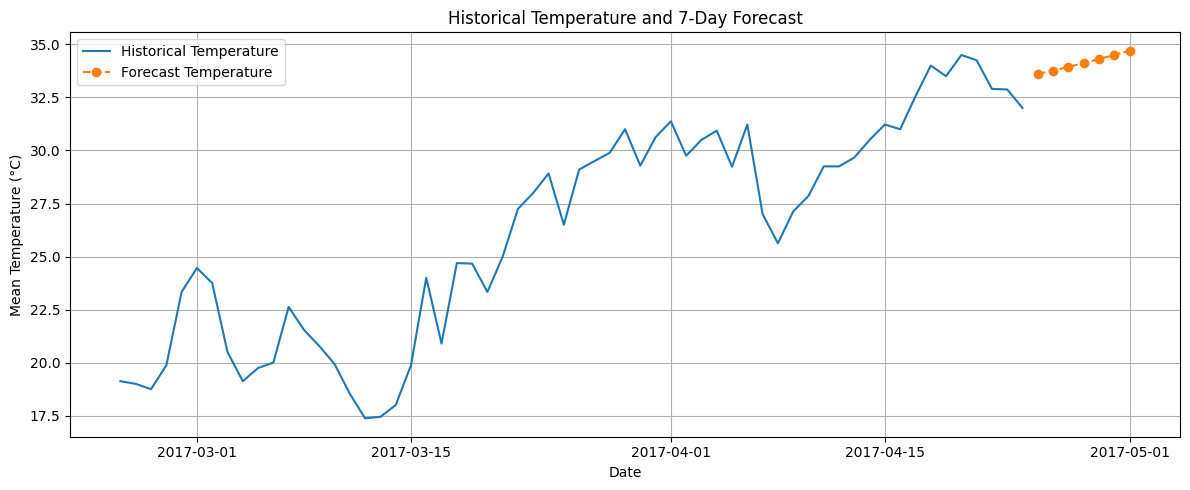

In [27]:
plt.figure(figsize=(12, 5))

# Show recent historical temperatures
plt.plot(
    data["date"].iloc[-60:],
    data["meantemp"].iloc[-60:],
    label="Historical Temperature"
)

# Show future forecast
plt.plot(
    future_dates,
    future_predictions,
    marker="o",
    linestyle="--",
    label="Forecast Temperature"
)

plt.title("Historical Temperature and 7-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

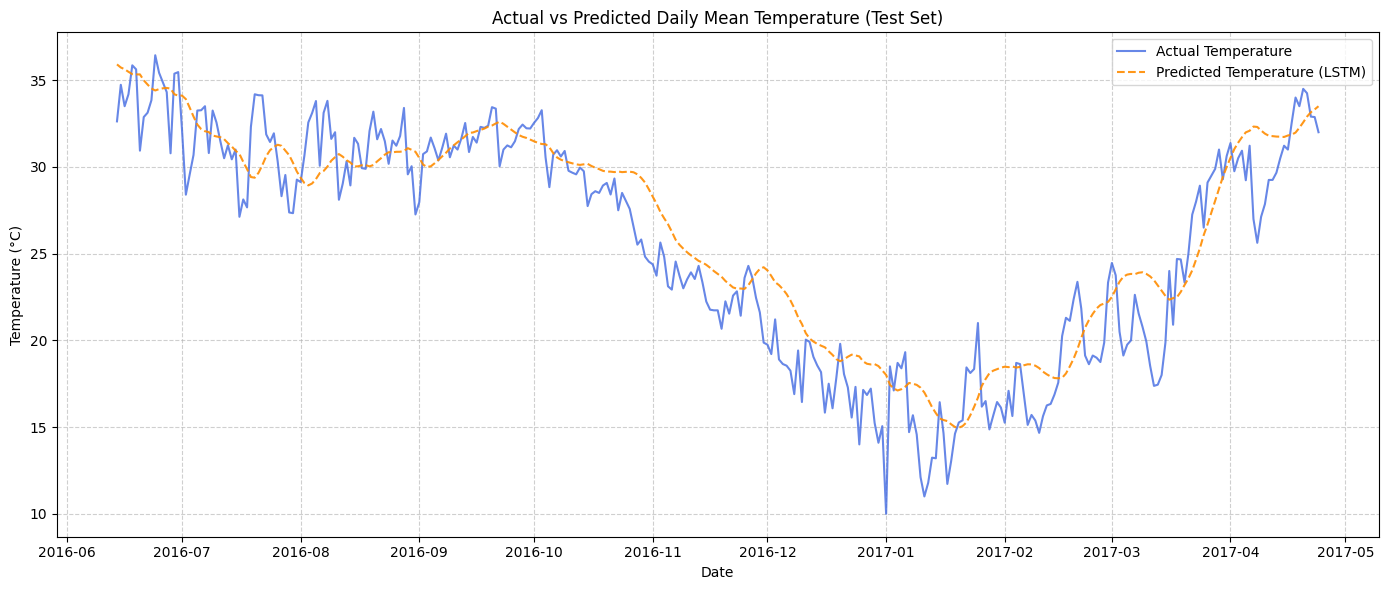

In [28]:
plt.figure(figsize=(14, 6))

# Get the corresponding dates for the test set
test_dates = data["date"].iloc[split_index:]

plt.plot(test_dates, y_actual, label="Actual Temperature", color="royalblue", alpha=0.8)
plt.plot(test_dates, y_predicted, label="Predicted Temperature (LSTM)", color="darkorange", linestyle="--", alpha=0.9)

plt.title("Actual vs Predicted Daily Mean Temperature (Test Set)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()